Find god taksonomi - https://www.census.gov/naics/?input=71&chart=2017 ? foursquare?



In [1]:
from datetime import datetime, timedelta, date
import math
from pathlib import Path

import duckdb
import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
import numpy as np
import orjson
import pandas as pd
import polars as pl
import seaborn as sns
import shapely
import statsmodels.formula.api as smf
import statsmodels.api as sm
from tqdm import tqdm

from wpp import db
from wpp.segregation import data
from wpp.utils import project_root

In [27]:
# config
sns.set_theme(style="ticks")
pl.Config.set_engine_affinity("streaming")

root = project_root()
db_path = root / "wpp.duckdb"
con = db.connect(db_path, read_only=True)

## Static segregation

In [3]:
query = """
    WITH v AS (
        SELECT ID_STORE, SUM(VISITOR_COUNTS) AS TOTAL_VISITORS
        FROM visits
        GROUP BY ID_STORE
    ), h AS (
        SELECT c.CELL_ID, AVG(TMEAN) AS AVG_TMEAN
        FROM prism_cells c
        JOIN prism_t_daily t ON c.CELL_ID = t.CELL_ID
        GROUP BY c.cell_id
    ), top_naics AS (
        SELECT NAICS_CODE, NAICS_TITLE AS CATEGORY
        FROM naics
        WHERE LEN(NAICS_CODE) = 3
    )
    SELECT p.*, v.TOTAL_VISITORS AS VISITORS, CATEGORY, AVG_TMEAN
    FROM pois p
    JOIN v ON p.ID_STORE = v.ID_STORE
    LEFT JOIN h ON p.CELL_ID = h.CELL_ID
    LEFT JOIN top_naics tn ON LEFT(p.NAICS_CODE, 3) = tn.NAICS_CODE
    WHERE CBSAFP = '35620'
"""
pois_dim = con.sql(query).pl().with_columns(
    pl.len().over("TOP_CATEGORY").alias("NUM_CATEGORY_POIS")
)
top_categories = set(pois_dim.group_by("TOP_CATEGORY").len().top_k(6, by="len")["TOP_CATEGORY"])
pois_dim = pois_dim.with_columns(
    pl.when(pl.col("TOP_CATEGORY").is_in(top_categories))
        .then(pl.col("TOP_CATEGORY"))
        .otherwise(pl.lit("Other"))
        .alias("TOP_CATEGORY_K")
)
pois_dim.head()

ID_STORE,POI_GEOID,CBSAFP,PERSISTENT_ID,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,CATEGORY,AVG_TMEAN,NUM_CATEGORY_POIS,TOP_CATEGORY_K
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i64,"decimal[38,0]",str,f64,u32,str
"""5989304""","""360610112031""","""35620""","""A1_JENNYC-A""","""Jenny Craig""","""Jenny Craig, Inc.""","""476 3Rd Avenue Between 32Nd An…","""New York""","""NY""","""US""","""812191""","""Personal Care Services ""","""Diet and Weight Reducing Cente…",1970-01-01,2038-01-01,-73.966819,40.761269,"b""\x01\x01\x00\x00\x00\xbd\xaa\xb3Z\xe0}R\xc0\xb4:9CqaD@""",310325,101813,"""Personal and Laundry Services""",13.433693,15702,"""Personal Care Services """
"""6009761""","""360610163003""","""35620""","""A1_BDPAPA-A""","""Beard Papa's""","""Beard Papa's""","""2167 Broadway""","""New York""","""NY""","""US""","""722513""","""Restaurants and Other Eating P…","""Limited-Service Restaurants """,1970-01-01,2026-07-14,-73.981286,40.782209,"b""\x01\x01\x00\x00\x00g`\xe4e\xcd~R\xc0\x85\xd1\xacl\x1fdD@""",308919,8680,"""Food Services and Drinking Pla…",13.171926,58126,"""Restaurants and Other Eating P…"
"""6017366""","""340297227022""","""35620""","""A1_MBGL-A""","""Manhattan Bagel""","""Manhattan Bagel""","""860 Fischer Blvd""","""Toms River""","""NJ""","""US""","""722515""","""Restaurants and Other Eating P…","""Snack and Nonalcoholic Beverag…",2014-09-29,2038-01-01,-74.136837,39.972052,"b""\x01\x01\x00\x00\x00\x7f\xf8\xf9\xef\xc1\x88R\xc0u\x01/3l\xfcC@""",337016,30837,"""Food Services and Drinking Pla…",12.813201,58126,"""Restaurants and Other Eating P…"
"""6018879""","""340258096004""","""35620""","""A1_FRB-A""","""Frutta Bowls""","""Frutta Bowls""","""167 U.S. 9""","""Morganville""","""NJ""","""US""","""722513""","""Restaurants and Other Eating P…","""Limited-Service Restaurants """,2020-12-22,2038-01-01,-74.308799,40.347714,"b""\x01\x01\x00\x00\x00f\x82\xe1\\xc3\x93R\xc0A.q\xe4\x81,D@""",324367,14047,"""Food Services and Drinking Pla…",12.195046,58126,"""Restaurants and Other Eating P…"
"""6027558""","""340297139005""","""35620""","""A1_MALL-A""","""Mall""","""Riverwalk at Brick""","""2770 Hooper Avenue""","""Brick""","""NJ""","""US""","""531120""","""Lessors of Real Estate""","""Lessors of Nonresidential Buil…",1970-01-01,2038-01-01,-74.136842,40.05556,"b""\x01\x01\x00\x00\x00\x14\xcf\xd9\x02\xc2\x88R\xc0\xb6\xbd\xdd\x92\x1c\x07D@""",334206,416238,"""Real Estate""",12.638397,3390,"""Other"""


We can use different definitions. For now, we use an adapted POI segregation from [Moro et al.](https://www.nature.com/articles/s41467-021-24899-8)

> To measure the income segregation of each place $\alpha$ in the city, we compute the proportion of total time spent at that place $\alpha$ by each income quartile $q$, $\tau _{q, \alpha}$, defining separate quartiles for each city. We define full integration of a place as $\tau _{q, \alpha} = \frac{1}{4}$ for each $q$, that is, the total time spent at venue $\alpha$ is split evenly across our four income quartiles. We then define the income segregation for each place $\alpha$, $S_\alpha$, as any deviation from our idealized measure of integration:
> $$S_{\alpha} = \frac{2}{3}\sum_{q=1}^{4}\left|\tau_{q\alpha} - \frac{1}{4}\right|$$

This definition generalizes to any number of groups as

$$
S_{\alpha}^{\{n\}} = \frac{n}{2n - 2}\sum_{q=1}^{n}\left|\tau_{q\alpha} - \frac{1}{n}\right|
$$

In [4]:
query = """
    WITH bg AS (
        SELECT
            GEOID, CBSAFP, MEDIAN_HH_INCOME,
            NTILE(4) OVER (PARTITION BY CBSAFP ORDER BY MEDIAN_HH_INCOME ASC) AS INCOME_GROUP
        FROM block_groups_cbsa
        WHERE CBSAFP = '35620'
          AND MEDIAN_HH_INCOME IS NOT NULL
    ), filtered_pois AS (
        with x as (
            select
                v.ID_STORE, HOME_GEOID,
                SUM(VISITOR_COUNTS) AS VISITOR_COUNTS,
                COUNT(*) AS NUM_WEEKS
            from block_group_visits v
            join pois p on v.ID_STORE = p.ID_STORE
            where VISITOR_COUNTS >= 10
              and cbsafp = '35620'
            group by v.ID_STORE, HOME_GEOID
        )
        select 
            ID_STORE
        from x
        where NUM_WEEKS >= 5
          and VISITOR_COUNTS >= 100
        group by ID_STORE
        having COUNT(*) >= 10
    )
    SELECT 
        v.ID_STORE, INCOME_GROUP, 
        SUM(VISITOR_COUNTS) AS TOTAL_VISITORS, 
        COUNT(*) AS NUM_WEEKS
    FROM block_group_visits v
    JOIN bg ON v.HOME_GEOID = bg.GEOID
    WHERE v.ID_STORE IN (SELECT ID_STORE FROM filtered_pois)
    GROUP BY v.ID_STORE, INCOME_GROUP
"""
poi_group_visits = con.sql(query).pl()
poi_visits = (
    poi_group_visits
        .sort("INCOME_GROUP")
        .pivot("INCOME_GROUP", index="ID_STORE", column_naming="combine")
        .fill_null(0)
        .with_columns(
            pl.sum_horizontal(pl.selectors.starts_with("TOTAL_VISITORS_")).alias("TOTAL_VISITORS")
        )
        .with_columns(
            (
                pl.selectors.starts_with("TOTAL_VISITORS_").cast(pl.Float64)
                / pl.col("TOTAL_VISITORS").replace({0: None})
            ).name.replace("TOTAL_VISITORS_", "TAU_")
        )
        .with_columns(
            (
                (2 / 3) * pl.sum_horizontal(
                    (pl.selectors.starts_with("TAU_") - (1/4)).abs()
                )
            ).alias("SEGREGATION")
        )
        .filter(pl.col("TOTAL_VISITORS") > 0)
)
poi_visits.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

ID_STORE,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,NUM_WEEKS_1,NUM_WEEKS_2,NUM_WEEKS_3,NUM_WEEKS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION
str,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",i64,i64,i64,i64,"decimal[38,0]",f64,f64,f64,f64,f64
"""11234937""",66195,165787,211593,317842,2143,4166,5325,5238,761417,0.086937,0.217735,0.277894,0.417435,0.260438
"""10261092""",159786,205477,170422,295178,831,999,768,975,830863,0.192313,0.247306,0.205114,0.355267,0.140356
"""11409077""",201808,194223,64361,19049,5219,4742,1884,691,479441,0.420924,0.405103,0.134242,0.039732,0.434702
"""12385112""",8959,14707,89054,90919,219,449,854,1608,203639,0.043995,0.072221,0.437313,0.446471,0.511713
"""10286055""",238415,226500,164657,129341,6959,5961,4801,4329,758913,0.314153,0.298453,0.216964,0.170429,0.150142


In [5]:
pois = pois_dim.join(poi_visits, on="ID_STORE")
categories = pois.group_by("TOP_CATEGORY").agg(
    pl.len().alias("NUM_POIS"),
    pl.col("SEGREGATION").mean(),
    ((pl.col("SEGREGATION") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("W_SEGREGATION"),
    pl.col("TOTAL_VISITORS").sum(),
    pl.col("TOTAL_VISITORS").mean().alias("AVG_VISITORS")
)

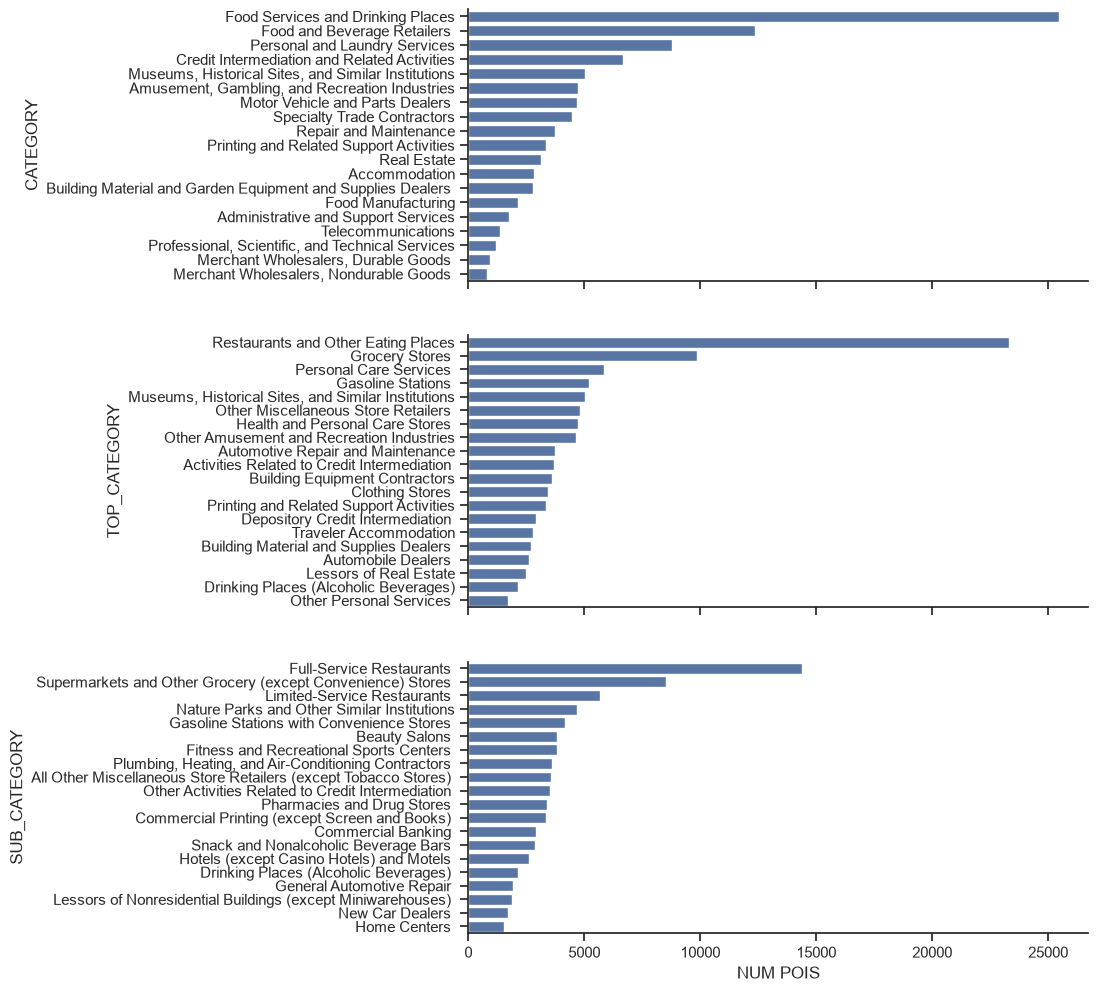

In [6]:
fig, axes = plt.subplots(3, sharex=True, figsize=(8, 12))
sns.barplot(
    pois.group_by("CATEGORY").len().sort("len", descending=True).top_k(20, by="len").to_pandas(),
    y="CATEGORY",
    x="len",
    ax=axes[0]
)
sns.barplot(
    pois.group_by("TOP_CATEGORY").len().sort("len", descending=True).top_k(20, by="len").to_pandas(),
    y="TOP_CATEGORY",
    x="len",
    ax=axes[1]
)
sns.barplot(
    pois.group_by("SUB_CATEGORY").len().sort("len", descending=True).top_k(20, by="len").to_pandas(),
    y="SUB_CATEGORY",
    x="len",
    ax=axes[2]
)
for ax in axes:
    ax.set_xlabel("NUM POIS")
sns.despine()

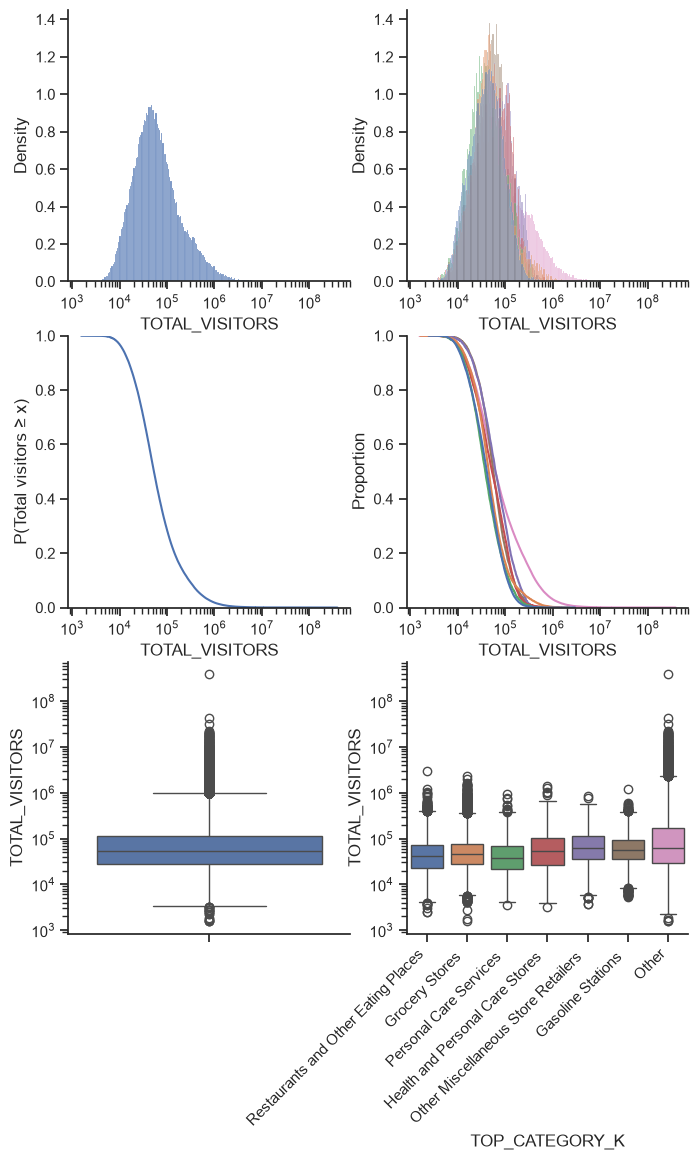

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(8, 12))
pois_pd = pois.with_columns(
    pl.col("TOTAL_VISITORS").cast(pl.Float64),
    pl.col("SEGREGATION").cast(pl.Float64),  # in case this is Decimal too
).sort("NUM_CATEGORY_POIS", descending=True).to_pandas()
sns.histplot(
    pois_pd,
    x="TOTAL_VISITORS",
    stat="density",
    log_scale=True,
    ax=axes[0,0],
)
sns.histplot(
    pois_pd,
    x="TOTAL_VISITORS",
    hue="TOP_CATEGORY_K",
    common_bins=True,
    common_norm=False,
    stat="density",
    log_scale=True,
    ax=axes[0,1],
    legend=False
)
axes[0,0].sharex(axes[0,1])
axes[0,0].sharey(axes[0,1])

sns.ecdfplot(
    data=pois_pd,
    x="TOTAL_VISITORS",
    complementary=True,
    log_scale=True,
    ax=axes[1, 0],
)
sns.ecdfplot(
    data=pois_pd,
    x="TOTAL_VISITORS",
    hue="TOP_CATEGORY_K",
    complementary=True,
    log_scale=True,
    ax=axes[1, 1],
    legend=False,
)
axes[1,0].set_ylabel("P(Total visitors ≥ x)")
axes[1,0].sharex(axes[1,1])
axes[1,0].sharey(axes[1,1])

sns.boxplot(
    pois_pd,
    y="TOTAL_VISITORS",
    log_scale=True,
    ax=axes[2,0],
    legend=False
)

sns.boxplot(
    pois_pd,
    x="TOP_CATEGORY_K",
    y="TOTAL_VISITORS",
    log_scale=True,
    ax=axes[2,1],
    hue="TOP_CATEGORY_K",
    legend=False
)
axes[2,0].sharey(axes[2,1])
axes[2,1].tick_params("x", rotation=45, rotation_mode="xtick")

sns.despine()

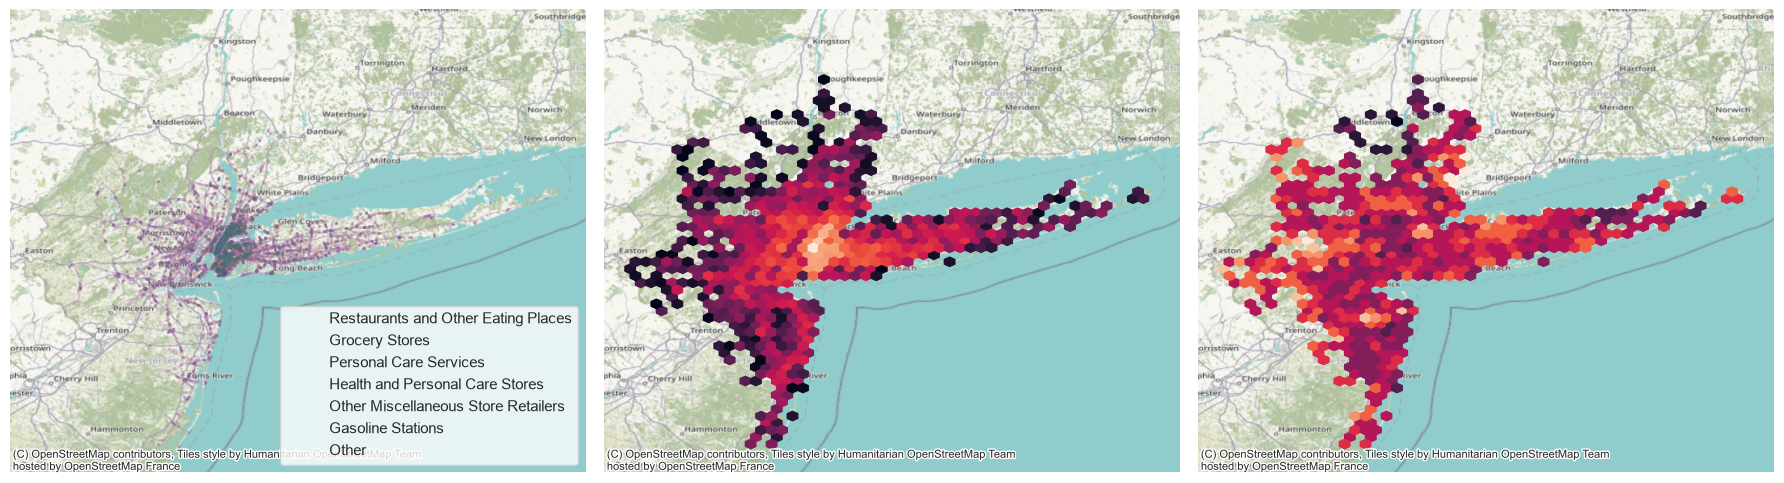

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18,5), sharex=True, sharey=True)

for i, ((label,), g) in enumerate(pois.sort("NUM_CATEGORY_POIS", descending=True).group_by("TOP_CATEGORY_K", maintain_order=True)):
    axes[0].scatter(g["LONGITUDE"], g["LATITUDE"], s=.1, alpha=.05, label=label, zorder=10-i)
axes[0].legend()
    
axes[1].hexbin(pois["LONGITUDE"], pois["LATITUDE"], mincnt=5, bins="log", gridsize=(50,30))
axes[2].hexbin(pois["LONGITUDE"], pois["LATITUDE"], pois["SEGREGATION"], mincnt=5, bins=10, gridsize=(50,30))

for ax in axes:
    cx.add_basemap(ax, zoom='auto', crs='EPSG:4326')
    ax.set_axis_off()
fig.tight_layout()

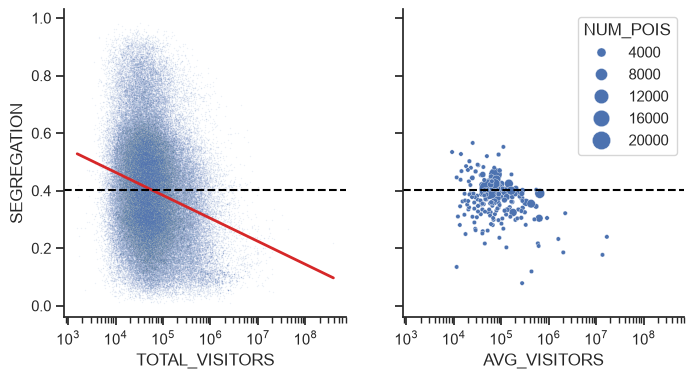

In [9]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))

sns.scatterplot(
    pois.to_pandas(),
    x="TOTAL_VISITORS",
    y="SEGREGATION",
    alpha=.1,
    s=1,
    ax=axes[0]
)
sns.scatterplot(
    categories.to_pandas(),
    x="AVG_VISITORS",
    y="SEGREGATION",
    size="NUM_POIS",
    sizes=(10, 200),
    ax=axes[1]
)

fit_data = pois.select(pl.col("TOTAL_VISITORS").cast(pl.Int32), "SEGREGATION").drop_nulls()
X = sm.add_constant(np.log10(fit_data["TOTAL_VISITORS"]))
model = sm.OLS(fit_data["SEGREGATION"], X).fit()
x_pred = np.geomspace(
    fit_data["TOTAL_VISITORS"].min(),
    fit_data["TOTAL_VISITORS"].max(),
    200,
)
y_pred = model.predict(
    sm.add_constant(np.log10(x_pred))
)
axes[0].plot(
    x_pred,
    y_pred,
    color="tab:red",
    linewidth=2,
    label=f"OLS ($R^2$ = {model.rsquared:.3f})",
)

mean_seg = pois["SEGREGATION"].mean()
for ax in axes:
    ax.set_xscale("log")
    ax.axhline(mean_seg, color="black", ls="--")
sns.despine()

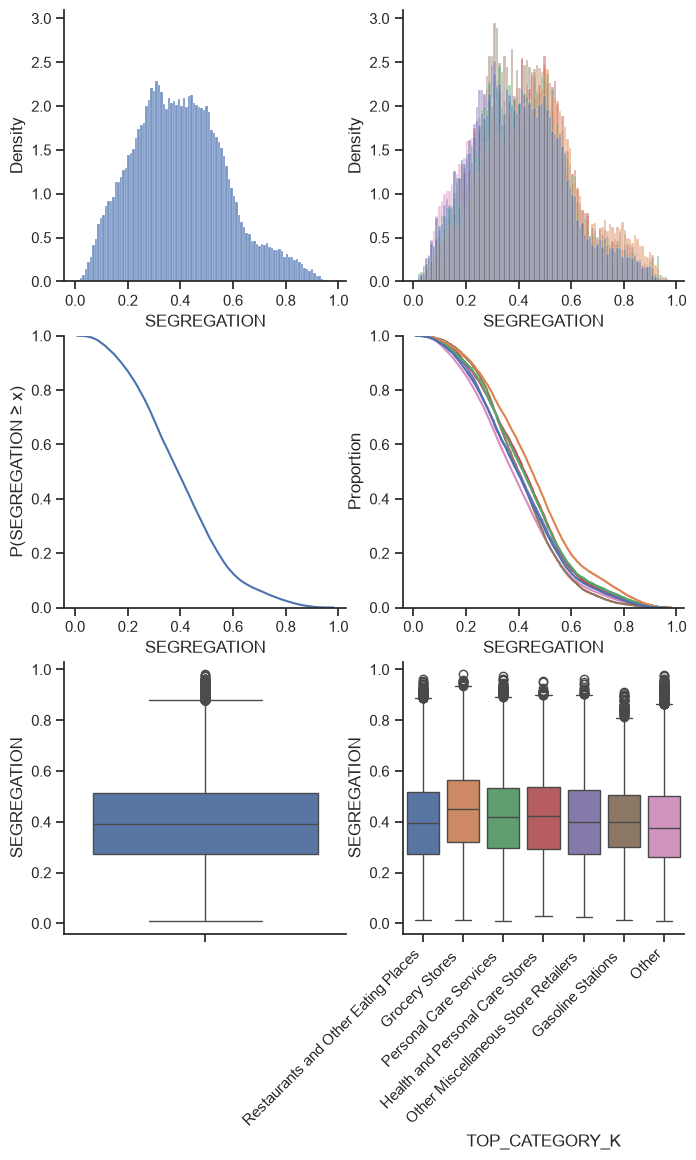

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(8, 12))
pois_pd = pois.with_columns(
    pl.col("TOTAL_VISITORS").cast(pl.Float64),
    pl.col("SEGREGATION").cast(pl.Float64),
).sort("NUM_CATEGORY_POIS", descending=True).to_pandas()
sns.histplot(
    pois_pd,
    x="SEGREGATION",
    stat="density",
    ax=axes[0,0],
)
sns.histplot(
    pois_pd,
    x="SEGREGATION",
    hue="TOP_CATEGORY_K",
    common_bins=True,
    common_norm=False,
    stat="density",
    ax=axes[0,1],
    legend=False
)
axes[0,0].sharex(axes[0,1])
axes[0,0].sharey(axes[0,1])

sns.ecdfplot(
    data=pois_pd,
    x="SEGREGATION",
    complementary=True,
    ax=axes[1, 0],
)
sns.ecdfplot(
    data=pois_pd,
    x="SEGREGATION",
    hue="TOP_CATEGORY_K",
    complementary=True,
    ax=axes[1, 1],
    legend=False,
)
axes[1,0].set_ylabel("P(SEGREGATION ≥ x)")
axes[1,0].sharex(axes[1,1])
axes[1,0].sharey(axes[1,1])

sns.boxplot(
    pois_pd,
    y="SEGREGATION",
    ax=axes[2,0],
    legend=False
)

sns.boxplot(
    pois_pd,
    x="TOP_CATEGORY_K",
    y="SEGREGATION",
    ax=axes[2,1],
    hue="TOP_CATEGORY_K",
    legend=False
)
axes[2,0].sharey(axes[2,1])
axes[2,1].tick_params("x", rotation=45, rotation_mode="xtick")

sns.despine()

In [11]:
top_categories = pl.concat([
    categories.filter(pl.col("NUM_POIS") >= 100).bottom_k(5, by="W_SEGREGATION"),
    categories.filter(pl.col("NUM_POIS") >= 100).top_k(5, by="W_SEGREGATION"),
])

<Axes: xlabel='AVG_TMEAN', ylabel='SEGREGATION'>

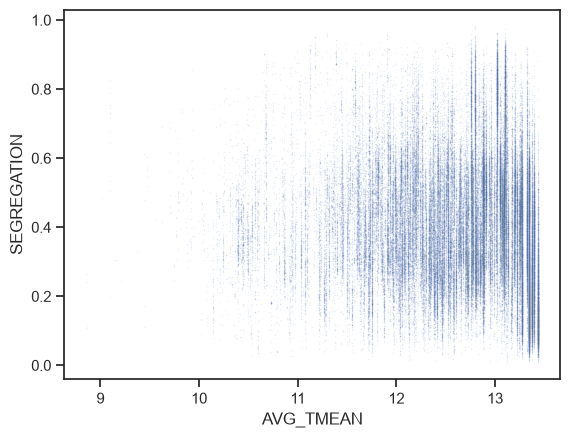

In [12]:
sns.scatterplot(
    pois.to_pandas(),
    x="AVG_TMEAN",
    y="SEGREGATION",
    alpha=.1,
    s=1,
)

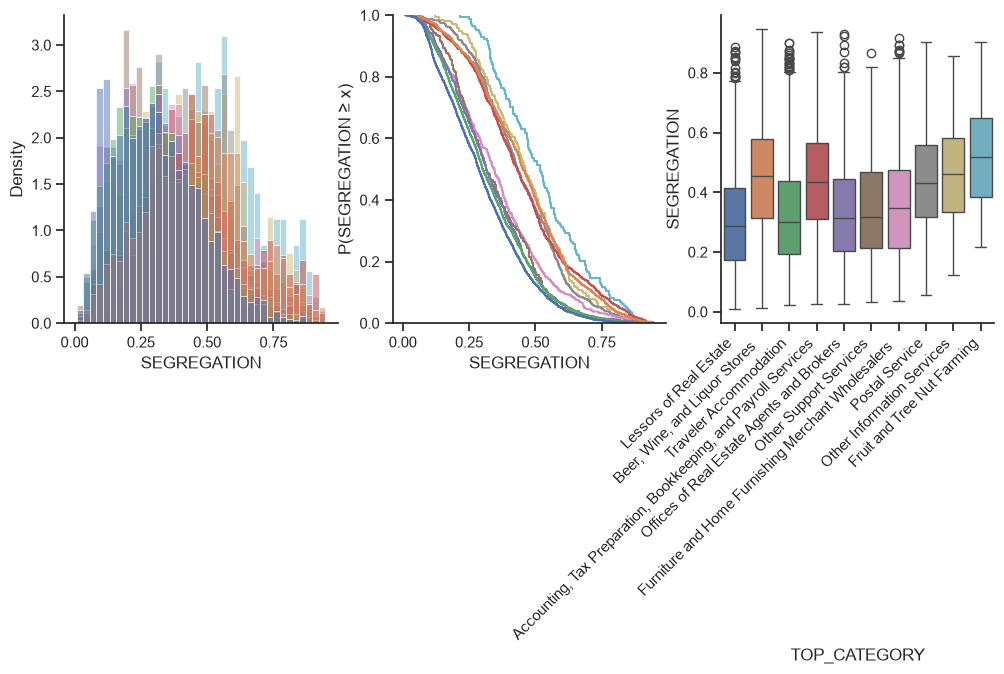

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

category_set = set(top_categories["TOP_CATEGORY"])
pois_pd = pois.filter(pl.col("TOP_CATEGORY").is_in(category_set)).with_columns(
    pl.col("TOTAL_VISITORS").cast(pl.Float64),
    pl.col("SEGREGATION").cast(pl.Float64),
).sort("SEGREGATION").to_pandas()

sns.histplot(
    pois_pd,
    x="SEGREGATION",
    hue="TOP_CATEGORY",
    common_bins=True,
    common_norm=False,
    stat="density",
    ax=axes[0],
    legend=False
)

sns.ecdfplot(
    data=pois_pd,
    x="SEGREGATION",
    hue="TOP_CATEGORY",
    complementary=True,
    ax=axes[1],
    legend=False,
)
axes[1].set_ylabel("P(SEGREGATION ≥ x)")

sns.boxplot(
    pois_pd,
    x="TOP_CATEGORY",
    y="SEGREGATION",
    ax=axes[2],
    hue="TOP_CATEGORY",
    legend=False
)
axes[2].tick_params("x", rotation=45, rotation_mode="xtick")

sns.despine()

## Weekly segregation

In [52]:
query = """
WITH bg AS (
    SELECT
        GEOID,
        CBSAFP,
        MEDIAN_HH_INCOME,
        NTILE(4) OVER (
            PARTITION BY CBSAFP
            ORDER BY MEDIAN_HH_INCOME
        ) AS INCOME_GROUP
    FROM block_groups_cbsa
    WHERE CBSAFP = '35620'
      AND MEDIAN_HH_INCOME IS NOT NULL
),

poi_home_summary AS (
    SELECT
        v.ID_STORE,
        v.HOME_GEOID,
        SUM(v.VISITOR_COUNTS) AS VISITOR_COUNTS,
        COUNT(*) AS NUM_WEEKS
    FROM block_group_visits v
    JOIN pois p
        ON v.ID_STORE = p.ID_STORE
    WHERE v.VISITOR_COUNTS >= 10
      AND p.CBSAFP = '35620'
    GROUP BY
        v.ID_STORE,
        v.HOME_GEOID
),

filtered_pois AS (
    SELECT ID_STORE
    FROM poi_home_summary
    WHERE NUM_WEEKS >= 5
      AND VISITOR_COUNTS >= 100
    GROUP BY ID_STORE
    HAVING COUNT(*) >= 10
),

poi_weeks AS (
    SELECT DISTINCT
        v.ID_STORE,
        v.DATE_RANGE_START,
        v.DATE_RANGE_END
    FROM block_group_visits v
    WHERE v.ID_STORE IN (
        SELECT ID_STORE
        FROM filtered_pois
    )
),

poi_temperature_weekly AS (
    SELECT
        pw.ID_STORE,
        pw.DATE_RANGE_START,
        pw.DATE_RANGE_END,
        AVG(t.TMEAN) AS AVG_TMEAN,
        AVG(t.TMIN) AS AVG_TMIN,
        AVG(t.TMAX) AS AVG_TMAX,
        COUNT(t.DATE) AS NUM_TEMPERATURE_DAYS
    FROM poi_weeks pw
    JOIN pois p
        ON pw.ID_STORE = p.ID_STORE
    LEFT JOIN prism_t_daily t
        ON p.CELL_ID = t.CELL_ID
       AND t.DATE >= pw.DATE_RANGE_START
       AND t.DATE <= pw.DATE_RANGE_END
    GROUP BY
        pw.ID_STORE,
        pw.DATE_RANGE_START,
        pw.DATE_RANGE_END
),

poi_group_visits_weekly AS (
    SELECT
        v.ID_STORE,
        v.DATE_RANGE_START,
        v.DATE_RANGE_END,
        bg.INCOME_GROUP,
        SUM(v.VISITOR_COUNTS) AS TOTAL_VISITORS
    FROM block_group_visits v
    JOIN bg
        ON v.HOME_GEOID = bg.GEOID
    WHERE v.ID_STORE IN (
        SELECT ID_STORE
        FROM filtered_pois
    )
    GROUP BY
        v.ID_STORE,
        v.DATE_RANGE_START,
        v.DATE_RANGE_END,
        bg.INCOME_GROUP
)

SELECT
    v.ID_STORE,
    v.DATE_RANGE_START,
    v.DATE_RANGE_END,
    v.INCOME_GROUP,
    v.TOTAL_VISITORS,
    t.AVG_TMEAN,
    t.AVG_TMIN,
    t.AVG_TMAX,
    t.NUM_TEMPERATURE_DAYS
FROM poi_group_visits_weekly v
LEFT JOIN poi_temperature_weekly t
    USING (
        ID_STORE,
        DATE_RANGE_START,
        DATE_RANGE_END
    )
ORDER BY
    v.ID_STORE,
    v.DATE_RANGE_START,
    v.INCOME_GROUP
"""

poi_group_visits_weekly = con.sql(query).pl()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [53]:
poi_visits_weekly = (
    poi_group_visits_weekly
    .sort("INCOME_GROUP")
    .pivot(
        "INCOME_GROUP",
        index=[
            "ID_STORE",
            "DATE_RANGE_START",
            "DATE_RANGE_END",
            "AVG_TMEAN",
            "AVG_TMIN",
            "AVG_TMAX",
            "NUM_TEMPERATURE_DAYS",
        ],
        column_naming="combine",
    )
    .fill_null(
        0,
        matches_supertype=False,
    )
    .with_columns(
        pl.sum_horizontal(
            pl.selectors.starts_with("TOTAL_VISITORS_")
        ).alias("TOTAL_VISITORS")
    )
    .with_columns(
        (
            pl.selectors.starts_with("TOTAL_VISITORS_").cast(pl.Float64)
            / pl.col("TOTAL_VISITORS").replace(0, None)
        ).name.replace("TOTAL_VISITORS_", "TAU_")
    )
    .with_columns(
        (
            (2 / 3)
            * pl.sum_horizontal(
                (pl.selectors.starts_with("TAU_") - 0.25).abs()
            )
        ).alias("SEGREGATION")
    )
    .filter(pl.col("TOTAL_VISITORS") > 0)
)

poi_visits_weekly.head()

ID_STORE,DATE_RANGE_START,DATE_RANGE_END,AVG_TMEAN,AVG_TMIN,AVG_TMAX,NUM_TEMPERATURE_DAYS,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION
str,datetime[μs],datetime[μs],f64,f64,f64,i64,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",f64,f64,f64,f64,f64
"""10000071""",2025-01-06 00:00:00,2025-01-12 00:00:00,-1.284364,-3.909686,1.340957,7,1081,393,98,null,1572,0.687659,0.25,0.062341,null,0.416879
"""10000071""",2025-01-13 00:00:00,2025-01-19 00:00:00,0.753164,-2.1068,3.613128,7,843,748,188,null,1779,0.473862,0.420461,0.105677,null,0.359097
"""10000071""",2025-01-20 00:00:00,2025-01-26 00:00:00,-4.866614,-8.205857,-1.527371,7,536,402,null,null,938,0.571429,0.428571,null,null,0.333333
"""10000071""",2025-01-27 00:00:00,2025-02-02 00:00:00,2.490921,-1.540829,6.522671,7,523,315,null,null,838,0.624105,0.375895,null,null,0.333333
"""10000071""",2025-02-03 00:00:00,2025-02-09 00:00:00,1.301636,-2.493471,5.096743,7,1687,705,141,141,2674,0.63089,0.26365,0.05273,0.05273,0.526053


In [29]:
query = """
    WITH bg AS (
        SELECT
            GEOID, CBSAFP, MEDIAN_HH_INCOME,
            NTILE(4) OVER (PARTITION BY CBSAFP ORDER BY MEDIAN_HH_INCOME ASC) AS INCOME_GROUP
        FROM block_groups_cbsa
        WHERE CBSAFP = '35620'
          AND MEDIAN_HH_INCOME IS NOT NULL
    ), filtered_pois AS (
        with x as (
            select
                v.ID_STORE, HOME_GEOID,
                SUM(VISITOR_COUNTS) AS VISITOR_COUNTS,
                COUNT(*) AS NUM_WEEKS
            from block_group_visits v
            join pois p on v.ID_STORE = p.ID_STORE
            where VISITOR_COUNTS >= 10
              and cbsafp = '35620'
            group by v.ID_STORE, HOME_GEOID
        )
        select 
            ID_STORE
        from x
        where NUM_WEEKS >= 5
          and VISITOR_COUNTS >= 100
        group by ID_STORE
        having COUNT(*) >= 10
    )
    SELECT 
        v.ID_STORE, DATE_RANGE_START, INCOME_GROUP, 
        SUM(VISITOR_COUNTS) AS TOTAL_VISITORS, 
        COUNT(*) AS NUM_WEEKS
    FROM block_group_visits v
    JOIN bg ON v.HOME_GEOID = bg.GEOID
    WHERE v.ID_STORE IN (SELECT ID_STORE FROM filtered_pois)
    GROUP BY v.ID_STORE, DATE_RANGE_START, INCOME_GROUP
"""
poi_group_visits_weekly = con.sql(query).pl()
poi_visits_weekly = (
    poi_group_visits_weekly
        .sort("INCOME_GROUP")
        .pivot("INCOME_GROUP", index=["ID_STORE", "DATE_RANGE_START"], column_naming="combine")
        .fill_null(0)
        .with_columns(
            pl.sum_horizontal(pl.selectors.starts_with("TOTAL_VISITORS_")).alias("TOTAL_VISITORS")
        )
        .with_columns(
            (
                pl.selectors.starts_with("TOTAL_VISITORS_").cast(pl.Float64)
                / pl.col("TOTAL_VISITORS").replace({0: None})
            ).name.replace("TOTAL_VISITORS_", "TAU_")
        )
        .with_columns(
            (
                (2 / 3) * pl.sum_horizontal(
                    (pl.selectors.starts_with("TAU_") - (1/4)).abs()
                )
            ).alias("SEGREGATION")
        )
        .filter(pl.col("TOTAL_VISITORS") > 0)
)
poi_visits_weekly.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

ID_STORE,DATE_RANGE_START,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,NUM_WEEKS_1,NUM_WEEKS_2,NUM_WEEKS_3,NUM_WEEKS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION
str,datetime[μs],"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",i64,i64,i64,i64,"decimal[38,0]",f64,f64,f64,f64,f64
"""10618069""",2025-01-06 00:00:00,1144,1608,1813,673,20,21,13,7,5238,0.218404,0.306987,0.346124,0.128484,0.204149
"""11230228""",2025-01-06 00:00:00,1410,1234,824,1480,68,45,39,47,4948,0.284964,0.249394,0.166532,0.299111,0.112099
"""8264962""",2025-01-06 00:00:00,195,147,0,0,6,2,0,0,342,0.570175,0.429825,0.0,0.0,0.666667
"""3870032""",2025-01-06 00:00:00,200,433,532,501,3,7,8,7,1666,0.120048,0.259904,0.319328,0.30072,0.173269
"""5554604""",2025-01-06 00:00:00,235,304,357,159,12,13,10,7,1055,0.222749,0.288152,0.338389,0.150711,0.16872


In [54]:
pois_weekly = pois_dim.join(poi_visits_weekly, on="ID_STORE")
categories_weekly = pois_weekly.group_by("TOP_CATEGORY", "DATE_RANGE_START").agg(
    pl.len().alias("NUM_POIS"),
    pl.col("SEGREGATION").mean(),
    ((pl.col("SEGREGATION") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("W_SEGREGATION"),
    pl.col("TOTAL_VISITORS").sum(),
    pl.col("TOTAL_VISITORS").mean().alias("AVG_VISITORS")
)

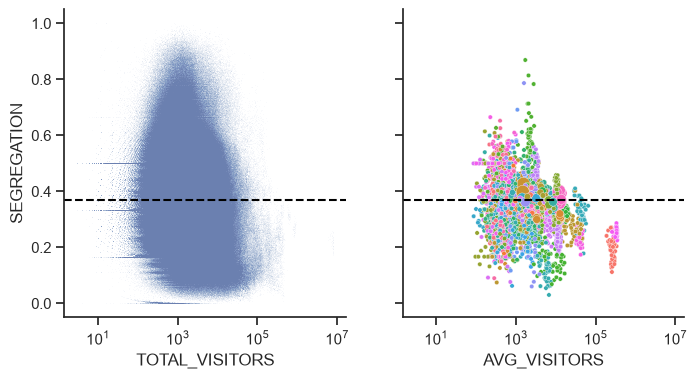

In [55]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))

sns.scatterplot(
    pois_weekly.to_pandas(),
    x="TOTAL_VISITORS",
    y="SEGREGATION",
    alpha=.04,
    s=.5,
    ax=axes[0]
)
sns.scatterplot(
    categories_weekly.to_pandas(),
    x="AVG_VISITORS",
    y="SEGREGATION",
    size="NUM_POIS",
    sizes=(10, 200),
    hue="TOP_CATEGORY",
    legend=False,
    ax=axes[1]
)

mean_seg = pois_weekly["SEGREGATION"].mean()
for ax in axes:
    ax.set_xscale("log")
    ax.axhline(mean_seg, color="black", ls="--")
sns.despine()

<Axes: xlabel='AVG_TMAX', ylabel='SEGREGATION'>

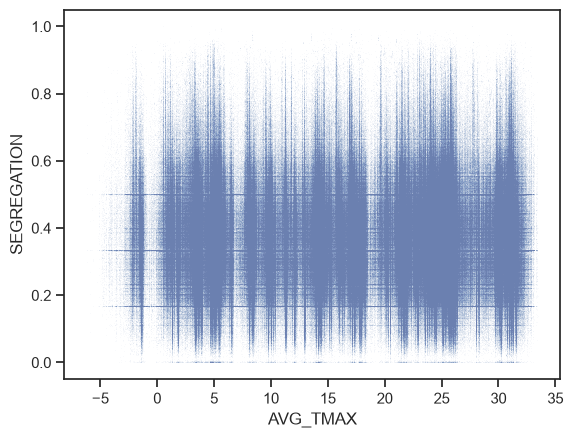

In [57]:
sns.scatterplot(
    pois_weekly.to_pandas(),
    x="AVG_TMAX",
    y="SEGREGATION",
    alpha=.04,
    s=.5,
)

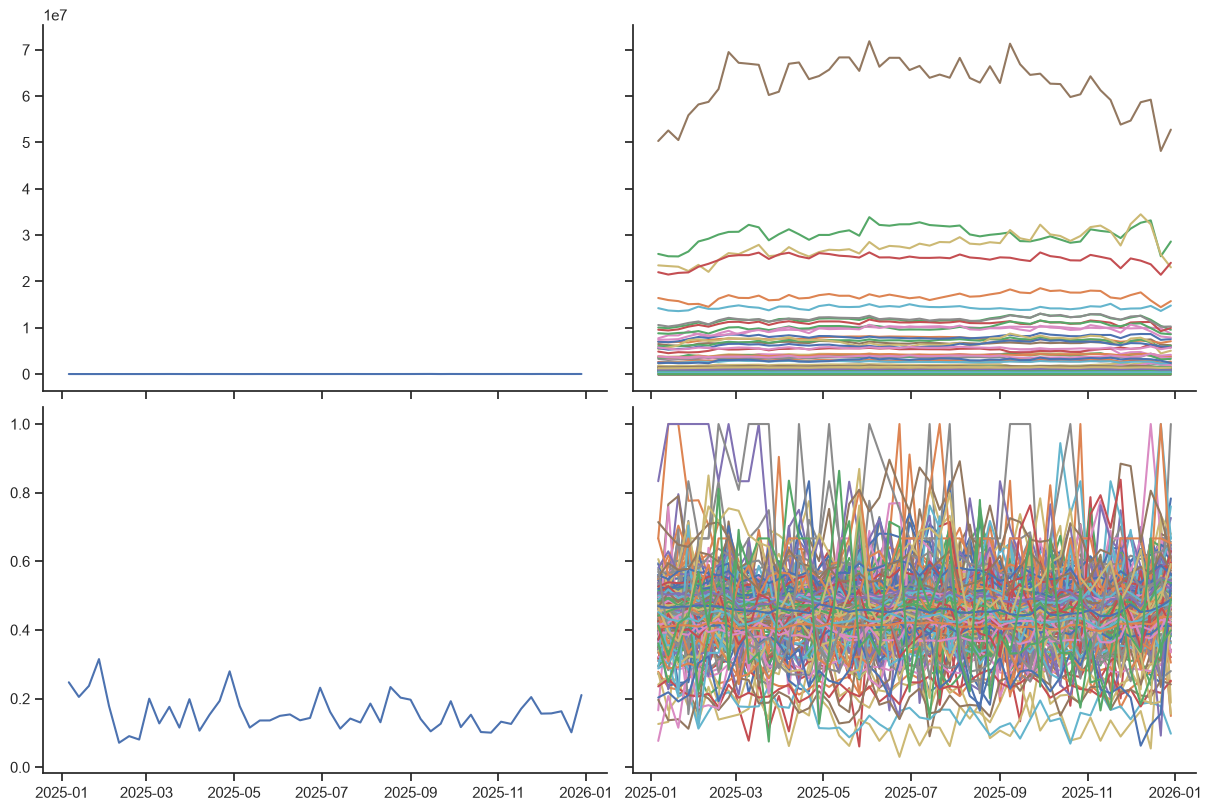

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey="row", constrained_layout=True)
for (id_store,), g in pois_weekly.group_by("ID_STORE"):
    g = g.sort("DATE_RANGE_START")
    axes[0,0].plot(g["DATE_RANGE_START"], g["TOTAL_VISITORS"])
    axes[1,0].plot(g["DATE_RANGE_START"], g["SEGREGATION"])
    break

for (category, ), g in categories_weekly.group_by("TOP_CATEGORY"):
    g = g.sort("DATE_RANGE_START")
    axes[0,1].plot(g["DATE_RANGE_START"], g["TOTAL_VISITORS"])
    axes[1,1].plot(g["DATE_RANGE_START"], g["SEGREGATION"])

sns.despine()

## Data is messed up exploration

In [14]:
pois.filter(
    pl.col("TOTAL_VISITORS") > 10_000,
    pl.col("SEGREGATION") == 1
)

ID_STORE,POI_GEOID,CBSAFP,PERSISTENT_ID,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,CATEGORY,AVG_TMEAN,NUM_CATEGORY_POIS,TOP_CATEGORY_K,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,NUM_WEEKS_1,NUM_WEEKS_2,NUM_WEEKS_3,NUM_WEEKS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i64,"decimal[38,0]",str,f64,u32,str,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",i64,i64,i64,i64,"decimal[38,0]",f64,f64,f64,f64,f64


In [15]:
con.sql("""
    SELECT *
    FROM block_group_visits
    WHERE ID_STORE = '8275101'
""").pl()

HOME_GEOID,ID_STORE,DATE_RANGE_START,DATE_RANGE_END,VISITOR_COUNTS
str,str,datetime[μs],datetime[μs],i32
"""340030242003""","""8275101""",2025-02-03 00:00:00,2025-02-09 00:00:00,704
"""340030242003""","""8275101""",2025-03-03 00:00:00,2025-03-09 00:00:00,697
"""340030242003""","""8275101""",2025-04-07 00:00:00,2025-04-13 00:00:00,692
"""340030242003""","""8275101""",2025-08-11 00:00:00,2025-08-17 00:00:00,115
"""340030242003""","""8275101""",2025-08-18 00:00:00,2025-08-24 00:00:00,115
…,…,…,…,…
"""340030242003""","""8275101""",2025-06-23 00:00:00,2025-06-29 00:00:00,117
"""340030242003""","""8275101""",2025-09-29 00:00:00,2025-10-05 00:00:00,102
"""340030242003""","""8275101""",2025-10-20 00:00:00,2025-10-26 00:00:00,112


In [16]:
df = con.sql("""
    SELECT
        * EXCLUDE (geom),
        ST_AsText(geom) AS wkt
    FROM block_groups
    WHERE CBSAFP = '35620'
""").df()

gbg = gpd.GeoDataFrame(
    df,
    geometry=gpd.GeoSeries.from_wkt(df["wkt"]),
    crs="EPSG:4269"
).drop(columns="wkt")

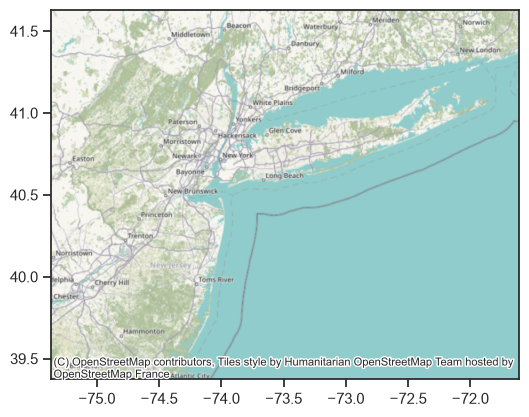

In [17]:
ax = gbg.boundary.plot(linewidth=.0, color="lightgrey")
sns.scatterplot(
    pois.filter(pl.col.ID_STORE == '8275101').to_pandas(),
    x="LONGITUDE",
    y="LATITUDE",
    ax=ax,
    zorder=10
)
cx.add_basemap(ax, crs="EPSG:4236")

In [18]:
pois.filter(pl.col.ID_STORE == "8275101")

ID_STORE,POI_GEOID,CBSAFP,PERSISTENT_ID,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,CATEGORY,AVG_TMEAN,NUM_CATEGORY_POIS,TOP_CATEGORY_K,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,NUM_WEEKS_1,NUM_WEEKS_2,NUM_WEEKS_3,NUM_WEEKS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i64,"decimal[38,0]",str,f64,u32,str,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",i64,i64,i64,i64,"decimal[38,0]",f64,f64,f64,f64,f64


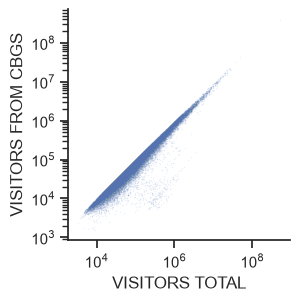

In [19]:
fig, ax = plt.subplots(figsize=(3,3))
sns.scatterplot(
    pois.to_pandas(),
    x="VISITORS",
    y="TOTAL_VISITORS",
    alpha=.1,
    s=1,
    ax=ax
)
vals = pois.to_pandas()[["VISITORS", "TOTAL_VISITORS"]]
lo = vals[vals > 0].min().min()
hi = vals.max().max()
lims = (10 ** np.floor(np.log10(lo)), 10 ** np.ceil(np.log10(hi)))
ticks = 10 ** np.arange(np.log10(lims[0]), np.log10(lims[1]) + 1)
ax.set(
    xlabel="VISITORS TOTAL",
    ylabel="VISITORS FROM CBGS",
    xticks=ticks,
    yticks=ticks,
    xscale="log",
    yscale="log",
)
ax.set_aspect('equal', adjustable='box')
sns.despine()

In [20]:
bg_dist = con.sql("""
    select v.ID_STORE, HOME_GEOID, SUM(VISITOR_COUNTS) AS VISITOR_COUNTS, COUNT(*) AS NUM_WEEKS
    from block_group_visits v
    join pois p on v.ID_STORE = p.ID_STORE
    where p.CBSAFP = '35620'
    group by v.ID_STORE, HOME_GEOID
""").pl()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:03<00:00,  1.27it/s]


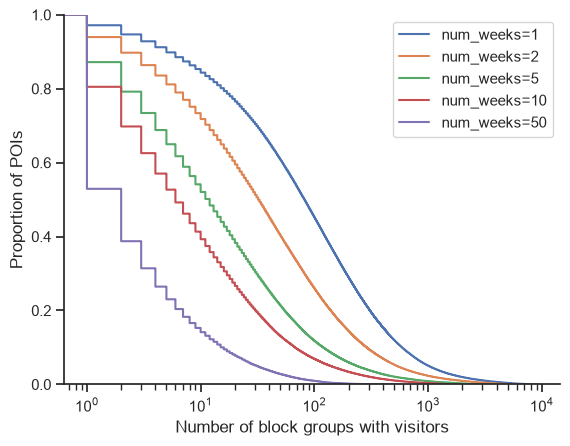

In [21]:
fig, ax = plt.subplots()
for t in tqdm([1, 2, 5, 10, 50]):
    d = bg_dist.filter(pl.col("NUM_WEEKS") >= t).group_by("ID_STORE").agg(pl.col("HOME_GEOID").n_unique().alias("NUM_BGS"))
    sns.ecdfplot(d["NUM_BGS"], complementary=True, label=f"num_weeks={t}")
ax.set_xscale("log")
ax.set_ylabel("Proportion of POIs")
ax.set_xlabel("Number of block groups with visitors")
ax.legend()
sns.despine()

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:03<00:00,  1.89it/s]


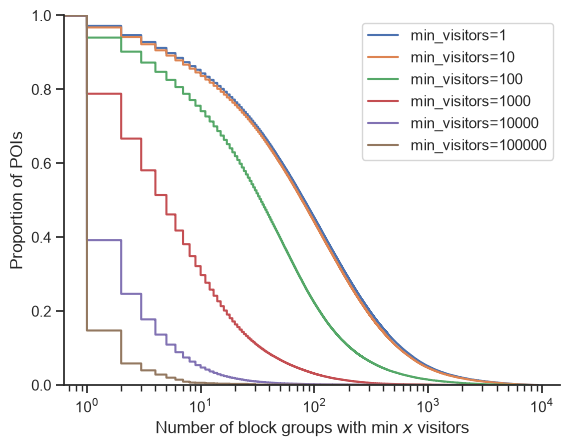

In [22]:
fig, ax = plt.subplots()
for t in tqdm([1, 10, 100, 1_000, 10_000, 100_000]):
    d = bg_dist.filter(pl.col("VISITOR_COUNTS") >= t).group_by("ID_STORE").agg(pl.col("HOME_GEOID").n_unique().alias("NUM_BGS"))
    sns.ecdfplot(d["NUM_BGS"], complementary=True, label=f"min_visitors={t}")
ax.set_xscale("log")
ax.set_ylabel("Proportion of POIs")
ax.set_xlabel("Number of block groups with min $x$ visitors")
ax.legend()
sns.despine()

In [23]:
query = """
with x as (
    select
        v.ID_STORE, HOME_GEOID,
        SUM(VISITOR_COUNTS) AS VISITOR_COUNTS,
        COUNT(*) AS NUM_WEEKS
    from block_group_visits v
    join pois p on v.ID_STORE = p.ID_STORE
    where VISITOR_COUNTS >= 10
      and cbsafp = '35620'
    group by v.ID_STORE, HOME_GEOID
)
select 
    ID_STORE, COUNT(*) AS NUM_BGS
from x
where NUM_WEEKS >= 5
  and VISITOR_COUNTS >= 100
group by ID_STORE
"""
test_data = con.sql(query).pl()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

/var/folders/2r/78dg63lx1vg81rz95pp5vkj00000gp/T/ipykernel_32136/4225440880.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


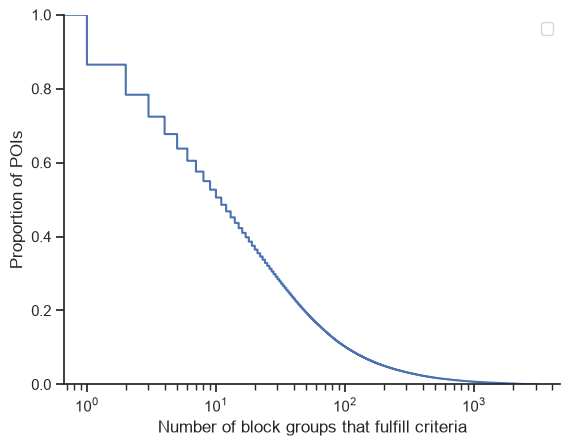

In [24]:
fig, ax = plt.subplots()
sns.ecdfplot(test_data["NUM_BGS"], complementary=True)
ax.set_xscale("log")
ax.set_ylabel("Proportion of POIs")
ax.set_xlabel("Number of block groups that fulfill criteria")
ax.legend()
sns.despine()

In [25]:
con.close()